<a href="https://colab.research.google.com/github/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/blob/main/SVD/svd_applications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**SVD APPLICATIONS**
---
This notebook shows the importance of SVD through different applications such as image compression and machine learning.



**IMPORT LIBRARIES**

In [119]:
import numpy as np
import cv2
import math
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
from scipy.optimize import curve_fit


**LOAD RESOURCES**


In [48]:
print("Loading Images...")
base_url = "https://raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/SVD/images/"

for i in range(1, 17):
    img_name = f"img_{i}.jpg"
    url = f"{base_url}{img_name}"
    !wget -q {url} -O {img_name}

Loading Images...


#**IMAGE COMPRESSION**
---

**CHOOSE IMAGE (1-16)**

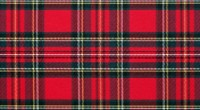

In [187]:
img=cv2.imread("img_15.jpg")
cv2_imshow(img)

**SEPARATE CHANNELS**

Blue Channel:


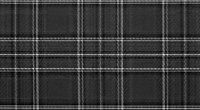

Red Channel:


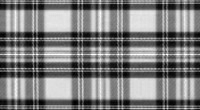

Green Channel:


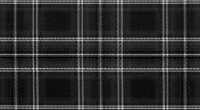

In [188]:
blue_channel=img[:,:,0]
green_channel=img[:,:,1]
red_channel=img[:,:,2]
print("Blue Channel:")
cv2_imshow(blue_channel)
print("Red Channel:")
cv2_imshow(red_channel)
print("Green Channel:")
cv2_imshow(green_channel)



**COMPUTE SVD PER CHANNEL**

In [189]:
blue_U, blue_S, blue_Vt = np.linalg.svd(blue_channel, full_matrices=True)
green_U, green_S, green_Vt = np.linalg.svd(green_channel, full_matrices=True)
red_U, red_S, red_Vt = np.linalg.svd(red_channel, full_matrices=True)
singular_values_chanels=np.array([blue_S,red_S,green_S])

**PLOT SINGULAR VALUES WITH LOG TRANSFORMATION**

Text(0, 0.5, 'Log Singular Value')

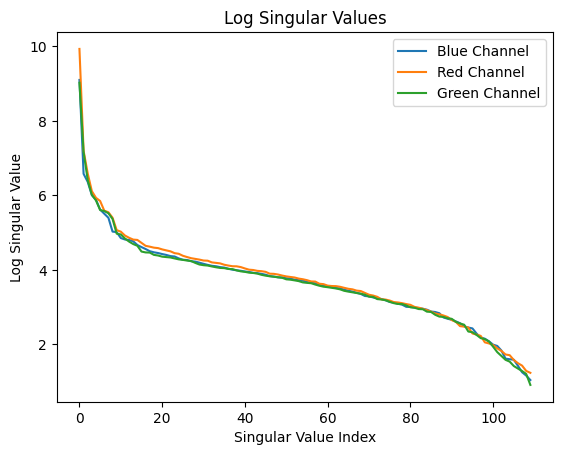

In [190]:
n_singular_values=min(img.shape[0],img.shape[1])
index=np.arange(0,n_singular_values)
for i in singular_values_chanels:
  plt.plot(index,np.log(i))
plt.title("Log Singular Values")
plt.legend(["Blue Channel","Red Channel","Green Channel"])
plt.xlabel("Singular Value Index")
plt.ylabel("Log Singular Value")


**CALCULATE PONDERATE CUMULATIVE SUM**

Text(0, 0.5, 'Cumulative Ponderate Singular Value')

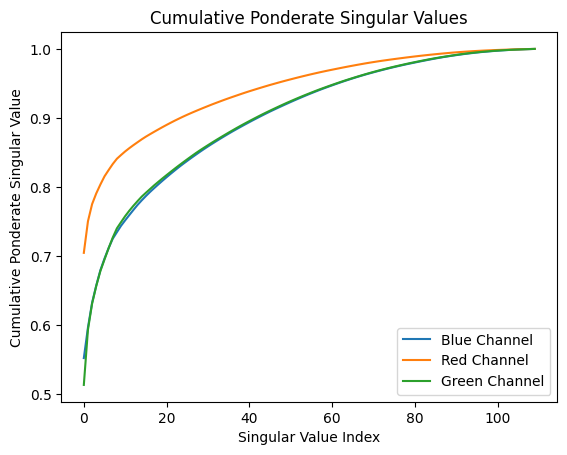

In [191]:
cum_ponderate_singular_values_list=[]
for i in singular_values_chanels:
  sum_singular_values=np.sum(i)
  ponderate_singular_values=i/sum_singular_values
  cum_ponderate_singular_values=np.cumsum(ponderate_singular_values)
  cum_ponderate_singular_values_list.append(cum_ponderate_singular_values)
  plt.plot(index,cum_ponderate_singular_values)
plt.title("Cumulative Ponderate Singular Values")
plt.legend(["Blue Channel","Red Channel","Green Channel"])
plt.xlabel("Singular Value Index")
plt.ylabel("Cumulative Ponderate Singular Value")

**GET SINGULAR VALUES THAT KEEP 95% OF THE INFORMATION**

In [192]:
retained_singular_values = []
for i in range(len(singular_values_chanels)):
  singular_values=singular_values_chanels[i]
  cum_ponderate_singular_values=cum_ponderate_singular_values_list[i]
  retained_channel_singular_values=singular_values[cum_ponderate_singular_values<=0.95]
  retained_singular_values.append(retained_channel_singular_values)

**PLOT RETAINED SINGULAR VALUES WITH LOG TRANSFORMATION**

Text(0, 0.5, 'Log Retained Singular Value')

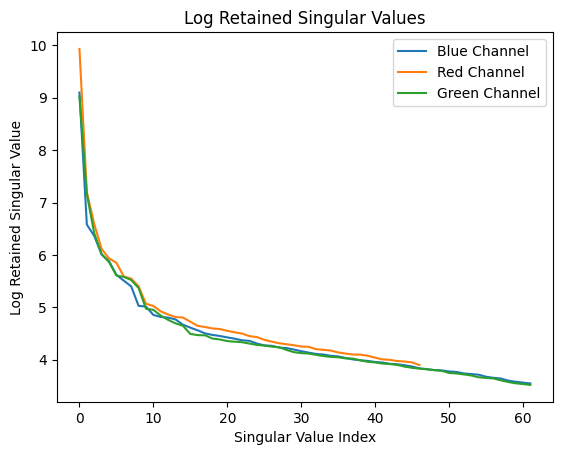

In [193]:
for i in retained_singular_values:
  index=np.arange(0,len(i))
  plt.plot(index,np.log(i))
plt.title("Log Retained Singular Values")
plt.legend(["Blue Channel","Red Channel","Green Channel"])
plt.xlabel("Singular Value Index")
plt.ylabel("Log Retained Singular Value")


**CHANNELS RESULT**

Blue Channel:


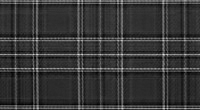

Red Channel:


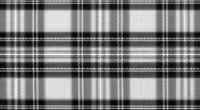

Green Channel:


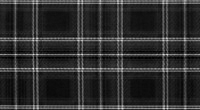

In [194]:
blue_U_retained=blue_U[:,:len(retained_singular_values[0])]
blue_Vt_retained=blue_Vt[:len(retained_singular_values[0]),:]
blue_channel_retained=blue_U_retained@np.diag(retained_singular_values[0])@blue_Vt_retained

red_U_retained=red_U[:,:len(retained_singular_values[1])]
red_Vt_retained=red_Vt[:len(retained_singular_values[1]),:]
red_channel_retained=red_U_retained@np.diag(retained_singular_values[1])@red_Vt_retained

green_U_retained=green_U[:,:len(retained_singular_values[2])]
green_Vt_retained=green_Vt[:len(retained_singular_values[2]),:]
green_channel_retained=green_U_retained@np.diag(retained_singular_values[2])@green_Vt_retained


print("Blue Channel:")
cv2_imshow(blue_channel_retained)
print("Red Channel:")
cv2_imshow(red_channel_retained)
print("Green Channel:")
cv2_imshow(green_channel_retained)



**RECONSTRUCT IMAGE**

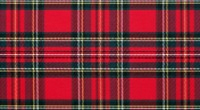

In [195]:
image_retained=np.zeros(img.shape)
image_retained[:,:,0]=blue_channel_retained
image_retained[:,:,1]=green_channel_retained
image_retained[:,:,2]=red_channel_retained
cv2_imshow(image_retained)

**AVERAGE SINGULAR VALUES OF CHANNELS**

Text(0, 0.5, 'Log Singular Value')

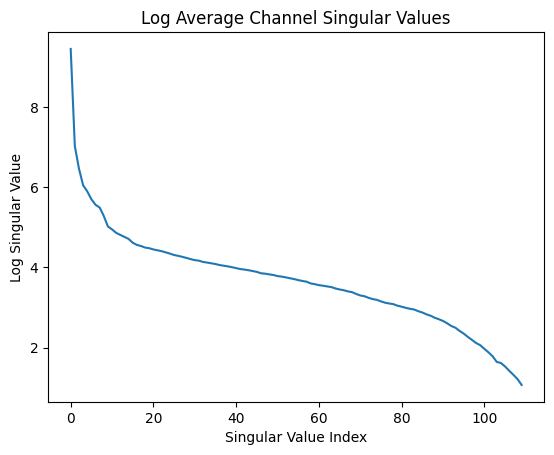

In [196]:
average_S=(blue_S+red_S+green_S)/3
index=np.arange(0,len(average_S))
plt.plot(index,np.log(average_S))
plt.title("Log Average Channel Singular Values")
plt.xlabel("Singular Value Index")
plt.ylabel("Log Singular Value")

**DISCARD FIRST K  PERCENTAGE OF SINGULAR VALUES**

Text(0, 0.5, 'Singular Value')

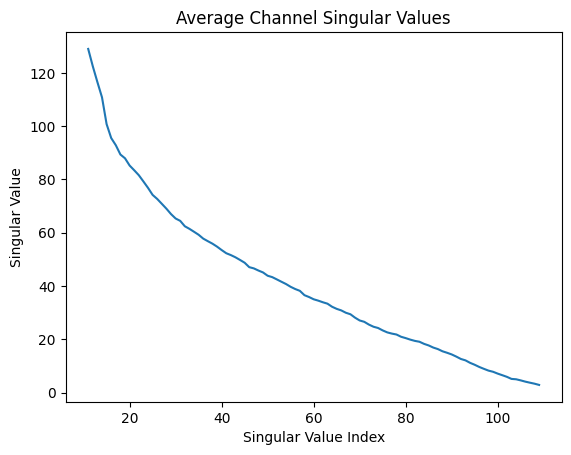

In [197]:
k=0.1
n=int(k*len(average_S))
k_average_S=average_S[n:]
k_index=index[n:]
plt.plot(k_index,k_average_S)
plt.title("Average Channel Singular Values")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value")


**DEFINE TYPE OF DECAY FUNCTIONS**

In [198]:
def linear(x,a,b):
  return a*x + b
def exponential(x,a,b,c):
  return a*np.exp((-b)*x) + c
def algebraic(x,a,b,c):
  return a*(x**(-b)) + c
decay_functions=[linear,exponential,algebraic]

**GET BEST FIT-CURVE PARAMETERS OF DECAY FUNCTIONS AND ERRORS**

/tmp/ipykernel_827/2782460972.py:4: RuntimeWarning: overflow encountered in exp
  return a*np.exp((-b)*x) + c
/tmp/ipykernel_827/2782460972.py:4: RuntimeWarning: overflow encountered in multiply
  return a*np.exp((-b)*x) + c
/tmp/ipykernel_827/2782460972.py:6: RuntimeWarning: overflow encountered in power
  return a*(x**(-b)) + c


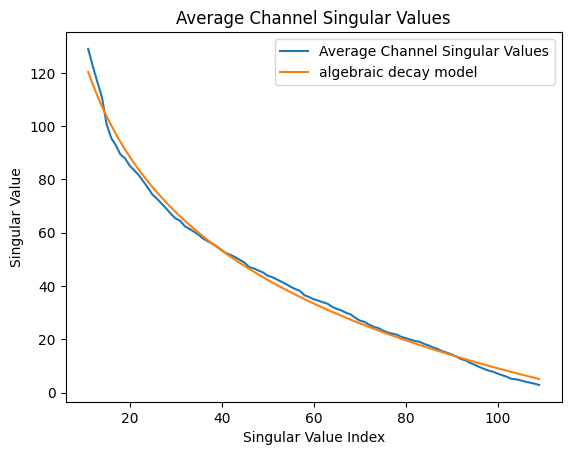

In [200]:
old_f_error=1e10
best_fit_curve=None
for f in decay_functions:
  popt,pcov = curve_fit(f, k_index, k_average_S)
  prediction = f(k_index, *popt)
  error = np.mean((k_average_S - prediction)**2)
  if error<old_f_error:
    old_f_error=error
    best_fit_curve=(f,popt)
best_fit_curve,curve_parameters=best_fit_curve
model_k_average_S=best_fit_curve(k_index,*curve_parameters)
plt.plot(k_index,k_average_S,label="Average Channel Singular Values")
plt.plot(k_index,model_k_average_S,label=f"{best_fit_curve.__name__} decay model")
plt.title("Average Channel Singular Values")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value")
plt.legend()